Step 0: Load and validate the data

In [1]:
# STEP 0: Load the cleaned dataset and check it is trustworthy
# pandas: the main library for working with tables (called "dataframes")
import pandas as pd

# matplotlib and seaborn: libraries for drawing charts
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import os

# The folder this notebook is running in
print("Current folder:", os.getcwd())

# The files Python can see in that folder
print(os.listdir())

Current folder: C:\Users\NITHYASHREE S
['.anaconda', '.conda', '.continuum', '.ipynb_checkpoints', '.ipython', '.jupyter', '3D Objects', 'AI powered credit card fraud detection.ipynb', 'AppData', 'Application Data', 'archive.zip', 'Contacts', 'Cookies', 'Customer_churn_prediction_project.ipynb', 'Documents', 'Downloads', 'Favorites', 'file1.txt', 'file2.txt', 'Links', 'Local Settings', 'Microsoft', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TM.blf', 'NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'P1-Customer purchase behaviour analysis using python(EDA).ipynb', 'PrintHood', 'Recent', 'Sales Trend Visualization.ipynb', 'Saved Games', 'Searches', 'SendTo', 'Start Menu', 'Telco-Customer-Churn - cleaned_dataset.csv', 'Templates'

In [3]:
# The name of your cleaned file. It must be in the same folder as this notebook.
# If you rename the file, change only this one line.
file_name = "Telco-Customer-Churn - cleaned_dataset.csv"

In [4]:
# Read the CSV file into a table called df ("data frame")
df = pd.read_csv(file_name)

In [5]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
# Number of rows and columns. Expected: (7043, 21)
print("Shape:", df.shape)

# Column names, data types and non-null counts
# Check that TotalCharges is float64 (a number), not object (text)
df.info()

# Missing values in each column. Expected: 0 everywhere
print("\nMissing values per column:\n", df.isnull().sum())

# Duplicate rows and duplicate customer IDs. Expected: 0 and 0
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customerIDs:", df["customerID"].duplicated().sum())

Shape: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   s

Step 1: overall churn rate

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


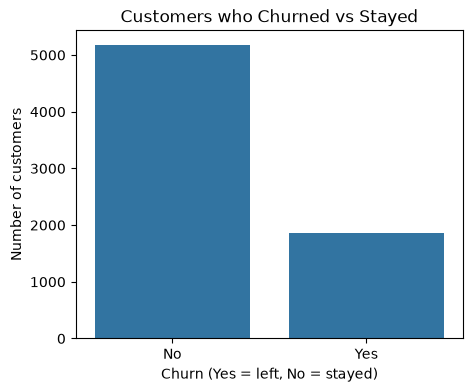

In [7]:
# Count how many customers left (Yes) and stayed (No)
# Expected: about 5,174 "No" and 1,869 "Yes"
print(df["Churn"].value_counts())

# The same as percentages. Expected: about 26.5% "Yes"
print((df["Churn"].value_counts(normalize=True) * 100).round(1))

# Draw a bar chart of the two groups
plt.figure(figsize=(5, 4))
sns.countplot(x="Churn", data=df)
plt.title("Customers who Churned vs Stayed")
plt.xlabel("Churn (Yes = left, No = stayed)")
plt.ylabel("Number of customers")
plt.show()

Step 2: Churn rate by contract type

## Step 2: Churn rate by contract type
**Finding:** Month-to-month customers churn at about 43%, versus about 11% for one-year and 2.8% for two-year contracts. Contract length is the strongest separator so far.

Churn rate (%) by contract type:
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn_Flag, dtype: float64


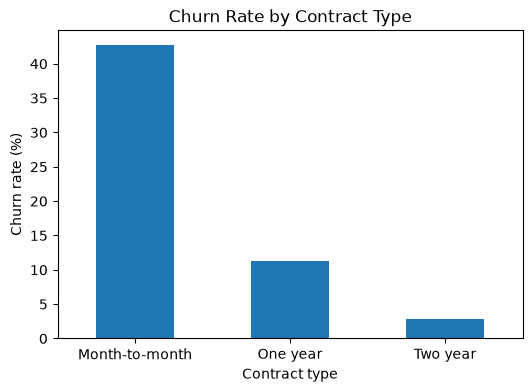

In [8]:
# Turn the text Yes/No into numbers: 1 = left, 0 = stayed
# The average of a column of 1s and 0s is the share of 1s, which is the churn rate
df["Churn_Flag"] = (df["Churn"] == "Yes").astype(int)

# Split customers into groups by contract type, average the 1/0 flag in each group,
# and multiply by 100 to get a percentage
contract_rate = df.groupby("Contract")["Churn_Flag"].mean() * 100

# Print the churn rate (%) for each contract type, rounded to 1 decimal place
print("Churn rate (%) by contract type:")
print(contract_rate.round(1))

# Draw one bar for each contract type
plt.figure(figsize=(6, 4))
contract_rate.plot(kind="bar")
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract type")
plt.ylabel("Churn rate (%)")

# Keep the labels horizontal so they are easy to read
plt.xticks(rotation=0)
plt.show()

Step 3: Tenure and monthly charges

## Step 3: Tenure and monthly charges
**Finding:** Customers who left had an average tenure of 18.0 months (vs 37.6 for those who stayed), and paid more per month (74.4 vs 61.3). Churn is concentrated among newer customers on higher bills.
**Caution:** These are associations, not proof of cause.

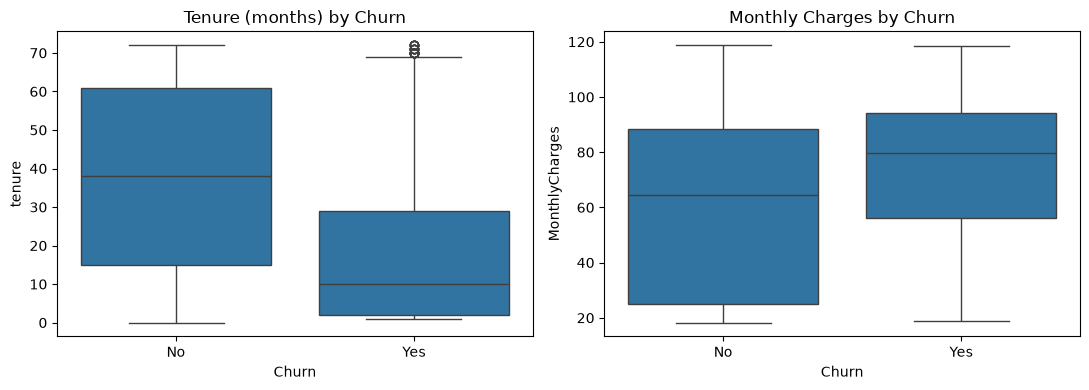

       tenure  MonthlyCharges
Churn                        
No       37.6            61.3
Yes      18.0            74.4


In [9]:
# Two charts side by side: 1 row, 2 columns
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Box plot 1: months with the company, for customers who stayed vs left
# The box is the middle 50% of customers, and the line inside is the median
sns.boxplot(x="Churn", y="tenure", data=df, ax=axes[0])
axes[0].set_title("Tenure (months) by Churn")

# Box plot 2: monthly charges, for customers who stayed vs left
sns.boxplot(x="Churn", y="MonthlyCharges", data=df, ax=axes[1])
axes[1].set_title("Monthly Charges by Churn")

# Stop the charts from overlapping, then display them
plt.tight_layout()
plt.show()

# The averages for each group as numbers
print(df.groupby("Churn")[["tenure", "MonthlyCharges"]].mean().round(1))

Step 4: Other segments

## Step 4: Other customer segments
**Findings:** Churn is highest for fiber optic customers (about 42%), electronic check payers (about 45%), customers without tech support (about 42%), paperless-billing customers (about 33%) and senior citizens (41.7%).
**Caution:** These groups overlap (for example, fiber customers also pay more), so these are associations, not proof of cause.


Churn rate (%) by InternetService:
InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn_Flag, dtype: float64

Churn rate (%) by PaymentMethod:
PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1
Name: Churn_Flag, dtype: float64

Churn rate (%) by TechSupport:
TechSupport
No                     41.6
No internet service     7.4
Yes                    15.2
Name: Churn_Flag, dtype: float64

Churn rate (%) by PaperlessBilling:
PaperlessBilling
No     16.3
Yes    33.6
Name: Churn_Flag, dtype: float64

Churn rate (%) by SeniorCitizen:
SeniorCitizen
0    23.6
1    41.7
Name: Churn_Flag, dtype: float64


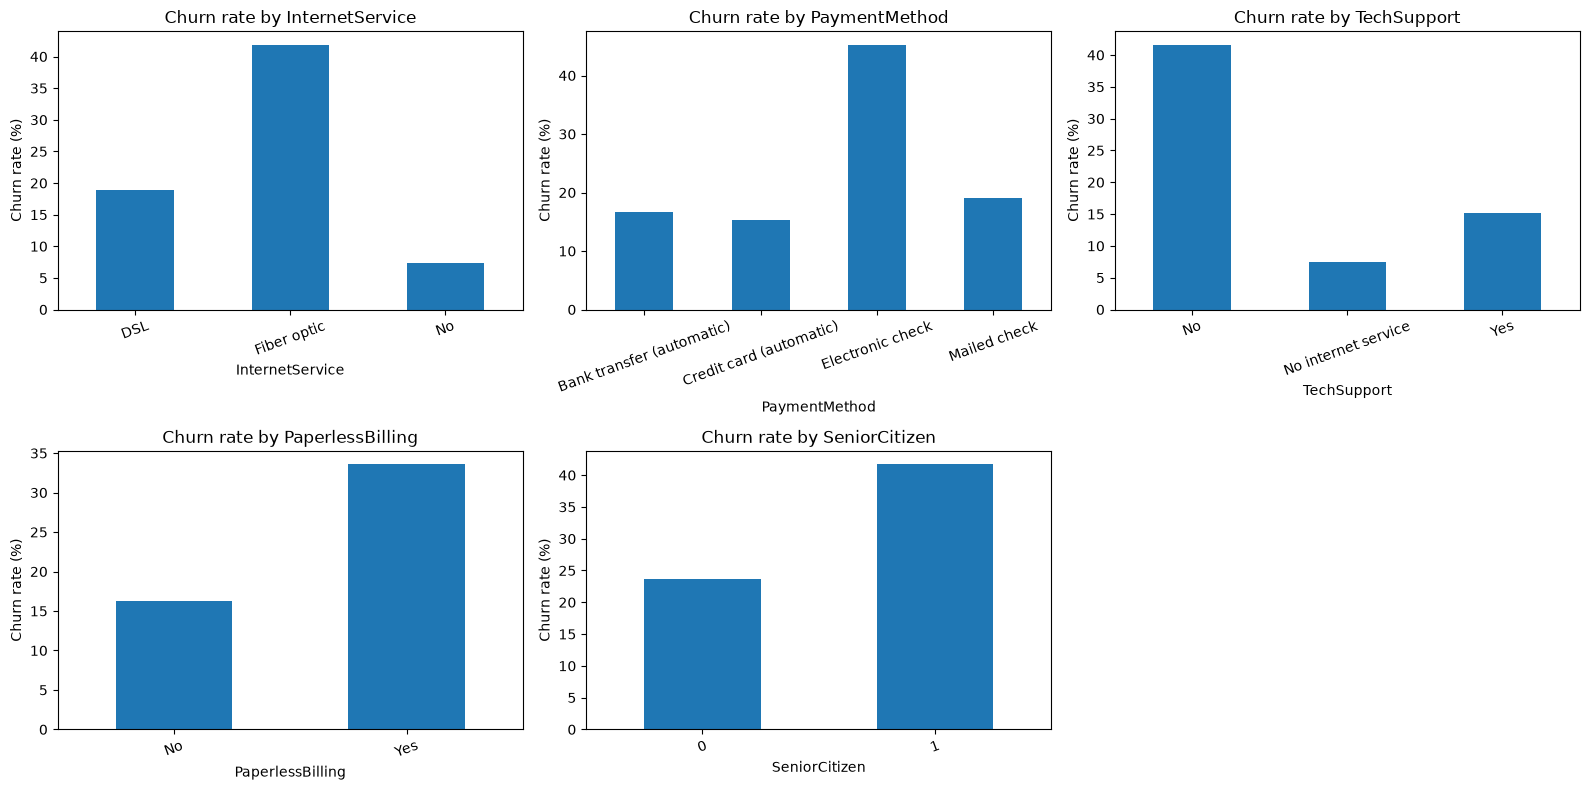

In [10]:
# The columns we want to compare. Each one splits customers into groups.
cols = ["InternetService", "PaymentMethod", "TechSupport",
        "PaperlessBilling", "SeniorCitizen"]

# Print the churn rate (%) for each group inside each column
for col in cols:
    # Group by the column, average the 1/0 churn flag, and turn it into a percentage
    rate = (df.groupby(col)["Churn_Flag"].mean() * 100).round(1)
    print(f"\nChurn rate (%) by {col}:")
    print(rate)

# A grid of charts: 2 rows x 3 columns, 16 wide and 8 tall
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

# Turn the 2D grid into a simple list so we can loop over it
axes = axes.flatten()

# Draw one bar chart for each column
for i, col in enumerate(cols):
    # Churn rate (%) for each group of this column
    rate = df.groupby(col)["Churn_Flag"].mean() * 100
    # Draw it in the i-th chart area
    rate.plot(kind="bar", ax=axes[i])
    # Title, y-axis label, and slightly tilted x labels so long names fit
    axes[i].set_title(f"Churn rate by {col}")
    axes[i].set_ylabel("Churn rate (%)")
    axes[i].tick_params(axis="x", rotation=20)

# There are 5 charts but 6 areas, so hide the unused one
axes[5].axis("off")

# Stop the charts from overlapping, then display them
plt.tight_layout()
plt.show()

Step 5, prepare the data for modelling

## Step 5: Data preparation
Dropped customerID, one-hot encoded the categorical columns (30 features), made an 80/20 stratified train/test split (5,634 / 1,409 rows, churn share 0.265 in both), and scaled tenure, MonthlyCharges and TotalCharges using statistics from the training set only to avoid data leakage.

In [11]:
# ------------------------------------------------------------
# STEP 5: Prepare the data for modelling
# ------------------------------------------------------------

# Tools for splitting and scaling the data
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# y is the target we want to predict: 1 = left, 0 = stayed (created in Step 2)
y = df["Churn_Flag"]

# X holds the clues (features) the model learns from.
# We drop customerID (just a label, no information) and the two churn columns
# (keeping them would leak the answer into the clues).
X = df.drop(columns=["customerID", "Churn", "Churn_Flag"])

# Models can't read words like "Yes" or "Fiber optic", so convert each text column
# into 0/1 columns (this is called one-hot encoding).
# drop_first=True removes one redundant column per feature.
# dtype=int makes the new columns 0/1 numbers.
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Check the size: expected about (7043, 30)
print("Features shape:", X.shape)

# See the final list of columns the model will use
print(list(X.columns))

Features shape: (7043, 30)
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


In [12]:
# Split into a training set (80%) to teach the model and a test set (20%) to check it
# stratify=y keeps the same churn share (about 26.5%) in both parts, which matters
# because churners are the minority
# random_state=42 makes the split the same every time you run it
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Make independent copies so we can safely change them in the next step
X_train = X_train.copy()
X_test = X_test.copy()

# Check the sizes: expected about 5,634 training rows and 1,409 test rows
print("Train:", X_train.shape, "| Test:", X_test.shape)

# Check the churn share in each part. Both should be about 0.265
print("Churn share in train:", round(y_train.mean(), 3))
print("Churn share in test:", round(y_test.mean(), 3))

Train: (5634, 30) | Test: (1409, 30)
Churn share in train: 0.265
Churn share in test: 0.265


In [13]:
# The three number columns have very different ranges (tenure 0-72, TotalCharges up to ~8,700).
# Scaling puts them on a similar range, which helps Logistic Regression.
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

# Create the scaler
scaler = StandardScaler()

# fit_transform learns the average and spread from the TRAINING data only, then scales it
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])

# transform applies the SAME scaling to the test data without learning anything from it.
# This avoids "data leakage" (the test data must stay unseen).
X_test[num_cols] = scaler.transform(X_test[num_cols])

# Quick check: scaled training columns should have an average near 0
print(X_train[num_cols].mean().round(2))

tenure           -0.0
MonthlyCharges   -0.0
TotalCharges      0.0
dtype: float64


## Steps 6 and 7: Model comparison
Compared Logistic Regression and Random Forest (both with class_weight="balanced") on a held-out test set of 1,409 customers (374 churners).

**Findings:** Logistic Regression caught 78% of churners (recall 0.783, ROC-AUC 0.842) but with more false alarms (precision 0.504). Random Forest had higher accuracy (0.776) and precision (0.569) but caught only 64% of churners.
**Decision:** Logistic Regression is the final model because missing a churner is costlier than an unneeded retention offer, and it is easier to explain.
**Note:** Accuracy is misleading here; predicting "stays" for everyone would score about 73.5%.

Step 6: Train and compare models

In [14]:
# ------------------------------------------------------------
# STEP 6: Train two models and compare them on the test set
# ------------------------------------------------------------

# The models and the scores we will use
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

# A dictionary holding each model we want to try.
# class_weight="balanced" gives churners extra importance, because they are the minority.
# random_state=42 makes the results repeat exactly each time you run the cell.
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42),
}

# An empty list where we will store each model's scores
results = []

# Go through the models one by one
for name, model in models.items():
    # Teach the model using the TRAINING data only
    model.fit(X_train, y_train)

    # Predict 1 (will leave) or 0 (will stay) for each TEST customer
    pred = model.predict(X_test)

    # Predict the probability (0 to 1) that each test customer leaves.
    # [:, 1] picks the probability of class 1 (churn). ROC-AUC needs probabilities.
    proba = model.predict_proba(X_test)[:, 1]

    # Calculate the scores and save them
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),     # share of all predictions that were right
        "Precision": precision_score(y_test, pred),   # of those predicted to leave, how many really left
        "Recall": recall_score(y_test, pred),         # of those who really left, how many we caught
        "F1": f1_score(y_test, pred),                 # balance between precision and recall
        "ROC-AUC": roc_auc_score(y_test, proba),      # how well the model ranks leavers above stayers
    })

# Turn the list into a table and show it, rounded to 3 decimals
results_df = pd.DataFrame(results).round(3)
print(results_df)

                 Model  Accuracy  Precision  Recall     F1  ROC-AUC
0  Logistic Regression     0.738      0.504   0.783  0.614    0.842
1        Random Forest     0.776      0.569   0.642  0.603    0.827


Step 7: Confusion matrices

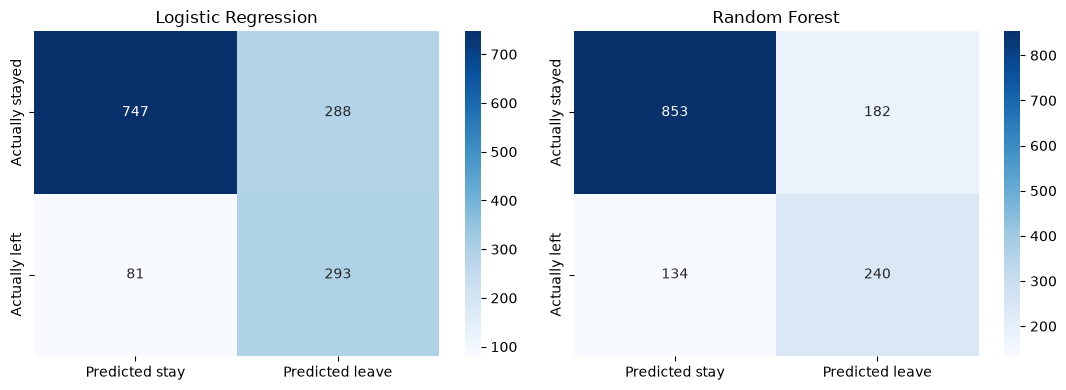

In [15]:
# ------------------------------------------------------------
# STEP 7: Confusion matrix for each model
# ------------------------------------------------------------

from sklearn.metrics import confusion_matrix

# Two charts side by side, one per model
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, model) in zip(axes, models.items()):
    # Predict again with the already trained model
    pred = model.predict(X_test)

    # Count: rows = what really happened, columns = what the model predicted
    cm = confusion_matrix(y_test, pred)

    # Draw it as a heatmap. annot=True prints the counts inside each box.
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Predicted stay", "Predicted leave"],
                yticklabels=["Actually stayed", "Actually left"])
    ax.set_title(name)

plt.tight_layout()
plt.show()

Step 8: Which features drive churn?

## Step 8: Feature importance
**Findings:** In Logistic Regression, a two-year contract (strongest), longer tenure and a one-year contract push predictions toward staying, while fiber optic internet is the strongest push toward leaving, followed by electronic check payment, streaming services and paperless billing. Add-ons such as tech support and online security, and having dependents, push toward staying. Random Forest ranks TotalCharges, tenure and MonthlyCharges highest, followed by contract type, fiber optic and electronic check.
**Caution:** Tenure, MonthlyCharges and TotalCharges overlap, so their individual coefficients should not be over-read. These are associations, not proof of cause.

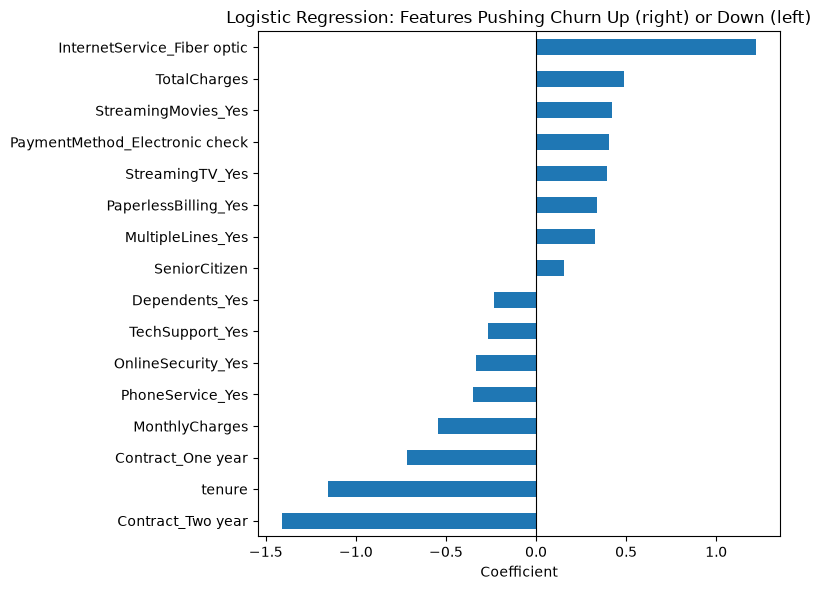

Top 10 Random Forest feature importances:
TotalCharges                      0.177
tenure                            0.166
MonthlyCharges                    0.152
Contract_Two year                 0.059
InternetService_Fiber optic       0.044
PaymentMethod_Electronic check    0.037
Contract_One year                 0.030
OnlineSecurity_Yes                0.028
gender_Male                       0.026
PaperlessBilling_Yes              0.024
dtype: float64


In [16]:
# ------------------------------------------------------------
# STEP 8: Which features matter most?
# ------------------------------------------------------------

# Take the trained Logistic Regression model out of our dictionary
lr = models["Logistic Regression"]

# coef_ holds one number per feature. Positive = more likely to churn, negative = less likely.
# Pair each number with its feature name and sort from lowest to highest.
coef = pd.Series(lr.coef_[0], index=X_train.columns).sort_values()

# Keep the 8 strongest "stay" factors (most negative) and the 8 strongest "leave" factors (most positive)
top = pd.concat([coef.head(8), coef.tail(8)])

# Horizontal bar chart: bars to the right push toward churn, bars to the left toward staying
plt.figure(figsize=(8, 6))
top.plot(kind="barh")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression: Features Pushing Churn Up (right) or Down (left)")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

# The Random Forest gives a second opinion: how much each feature helped its decisions
rf = models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=X_train.columns)
print("Top 10 Random Forest feature importances:")
print(importance.sort_values(ascending=False).head(10).round(3))

Step 9: Business recommendations

## Step 9: Business recommendations
1. **Target new month-to-month customers.** Churn is about 43% on month-to-month contracts against 2.8% on two-year contracts, and half the customers who left did so within about 10 months. Offer a discount or perk for moving to a one- or two-year contract in the first months.
2. **Use the model to rank risk.** Logistic Regression catches 78% of churners, so send retention offers to the top-ranked customers first.
3. **Review fiber optic service.** Fiber customers churn at about 42%, twice the DSL rate. Check price, reliability and support quality.
4. **Encourage automatic payment.** Electronic check users churn at about 45% against 15 to 19% for other methods.
5. **Promote tech support and online security add-ons.** Customers with tech support churn at about 15% vs 42% without it. This is an association, so test it before spending heavily.

## Summary
- 7,043 customers; 26.5% churned (imbalanced classes).
- Churn is concentrated among new, month-to-month customers, fiber optic users, electronic check payers and customers without tech support.
- Logistic Regression (recall 0.783, ROC-AUC 0.842) was chosen over Random Forest (recall 0.642, ROC-AUC 0.827).

## Limitations
- One snapshot of customers; no information about why each customer left.
- The model finds associations, not causes.
- Precision is about 0.50, so about half the flagged customers would not actually have left. The retention offer needs to be cheap enough to justify this.
- Results come from a single 80/20 split; cross-validation would give a steadier estimate.